# Chan et al. 2021 — Lung (SCLC/NSCLC, 10x) · 01 Preprocessing

Malignant-cell load → per-sample gap threshold → overdispersion → PCA → Harmony(`sample`) integration-strength sweep → UMAP → island removal → cell-cycle compartments → **Gate 1** (mixing + continuity on the regenerated embedding, per-neighbourhood iLISI). Every tunable is re-derived from this dataset (C1–C4); reference values are illustrative.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # 'Chan2021_Lung-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Lung'
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
raw_name = 'Data_' + name.replace('-1','')              # raw folder has no -1 suffix
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Chan2021_Lung-1 | category: Lung | raw: Data_Chan2021_Lung


### Load malignant cells
The loader auto-normalises counts (`Exp_data_UMIcounts.mtx`) and `log1p`s; `celltype` defaults to 'Malignant'. This cohort is predominantly **SCLC** (neuroendocrine) with minor NSCLC/LUAD, spanning the ASCL1/NEUROD1/POU2F3 transcriptional subtypes.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('X max %.2f (log1p of normalize_total counts)' % adata.X.max())
print('subtypes:', adata.obs['cell_subtype'].value_counts().to_dict())
print('disease :', adata.obs['disease'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Chan2021_Lung
Done.
full atlas: (86662, 26036)
malignant: (51052, 26036) | samples: 34
X max 8.51 (log1p of normalize_total counts)
subtypes: {'SCLC-A': 29099, 'SCLC-N': 18176, 'SCLC-P': 2989, 'NSCLC': 788}
disease : {'SCLC': 50310, 'LUAD': 742}


### Per-sample threshold — gap finding (C1/C3)
Sort per-sample malignant counts, find the largest multiplicative gap, and place the threshold at its geometric mean. No inherited constant.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [5243 4837 3946 3807 3766 3213 3078 2966 2746 2654 2546 2283 1910 1851
 1419 1265  958  763  689  517  183  165  102   92   15   11    9    7
    4    3    1    1    1    1]
largest gap: 92 -> 15 (ratio 6.13)
derived threshold (geometric mean across the gap) = 37
kept 24/34 samples -> 50999 cells


### Genes → overdispersion → PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3228 over-dispersed features (0:00:09) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3228


### Integration-strength sweep with per-neighbourhood iLISI (C1/C2)
Harmony on `sample` at increasing `theta`; the per-neighbourhood **iLISI** (effective number of samples among each cell's 90 nearest neighbours) measures mixing — never a single global scalar. iLISI rises from ~1 (fully sample-segregated) toward the plateau; the strongest integration that still plateaus is selected.

In [6]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique(); smp = adata.obs['sample'].values
rng = np.random.default_rng(SEED)
sub = rng.choice(adata.n_obs, size=min(8000, adata.n_obs), replace=False)
il_pre = np.median(ilisi(adata.obsm['X_pca'][sub,:20], smp[sub]))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = np.median(ilisi(adata.obsm['X_pca_harmony'][sub,:20], smp[sub]))
print(f'iLISI median | pre-Harmony {il_pre:.2f} of {nsamp} samples')
print('theta sweep iLISI:', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus 5->10; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)

iLISI median | pre-Harmony 1.00 of 24 samples
theta sweep iLISI: {2: np.float64(8.82), 5: np.float64(10.87), 10: np.float64(11.1)}
selected theta = 10 (mixing plateaus 5->10; strongest integration without collapse)


### Neighbours → UMAP (n_pcs=20)
`n_pcs=20` sits in the robust range used across the atlas (Kürten/Puram precedent 20–40); the elbow is not over-cut.

In [7]:
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

### Island removal — radius graph, keep largest component
Radius graph at 6× the median nearest-neighbour distance; keep the largest connected component (strictly conservative).

In [8]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy(); print('after island removal:', adata.shape[0])

removed 2 cells in 2 detached islands
after island removal: 50997


### Cell-cycle compartments
SCLC is highly proliferative. Proliferation here is a **graded** axis rather than a discrete second lobe (low-resolution Leiden returns a single blob), so the compartment is defined directly from the reported cell-cycle phase. Whether this proliferation axis confounds the developmental modules — and therefore whether the trajectory must be scoped — is tested in 02 before fitting.

In [9]:
# Proliferation is a graded axis here (SCLC is highly cycling), not a discrete second lobe:
# Leiden at low resolution returns a single blob, so the compartment is defined directly from
# the reported cell-cycle phase. Whether this proliferation axis confounds the developmental
# modules is tested in 02 (module vs g1s/g2m) before any trajectory scoping.
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
adata.obs['compartment'] = np.where(adata.obs['cycling'], 'Cycling', 'Quiescent')
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('cell-cycle phases:', adata.obs['cell_cycle_phase'].value_counts().to_dict())
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

cell-cycle phases: {'Not cycling': 29755, 'G1/S': 12297, 'G2/M': 5056, 'Intermediate': 3889}
compartments: {'Quiescent': 29755, 'Cycling': 21242}


### House orientation (X_umap_lin)
A rigid rotation (distance-preserving) aligning the manifold's principal axis to horizontal, with the more-cycling (progenitor) pole on the left, so the 02/03/04 panels share one consistent orientation (binding).

In [10]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
ang = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-ang),-np.sin(-ang)],[np.sin(-ang),np.cos(-ang)]])
xyr = c @ Rm.T
cyc = adata.obs['cycling'].values.astype(float)   # progenitor/high-cycling pole -> left
if np.average(xyr[:,0], weights=cyc) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'rigid rotation {np.degrees(ang):+.1f} deg; progenitor pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.29
rigid rotation -151.3 deg; progenitor pole on left; stored as X_umap_lin


### Gate 1 — mixing & continuity
Judged on the regenerated embedding: per-neighbourhood iLISI (integration) and a single connected component after island removal (continuity).

In [11]:
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
il_pre2 = np.median(ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre2:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {nsamp} samples')
print(f'{nsamp} samples share one continuous manifold (one connected component after island removal);')
print('both compartments contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 8.79 of 24 samples
24 samples share one continuous manifold (one connected component after island removal);
both compartments contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed.h5ad + samples.pdf

In [12]:
for col in adata.obs.columns:
    v = adata.obs[col]
    if v.dtype == object:
        conv = pd.to_numeric(v, errors='coerce')
        adata.obs[col] = conv if (v.notna().sum()>0 and conv.notna().sum()>=0.9*v.notna().sum()) else v.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (50997, 24117)


saved samples.pdf | cells: 50997


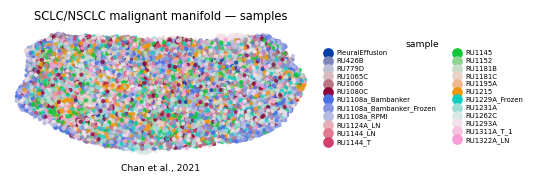

In [13]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('SCLC/NSCLC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])